# Nassau Candy Distributor - Product Profitability & Margin Performance Analysis

**Goal:** find out which products and divisions really make money, whether high-selling products are also profitable, and which products are a margin risk.

**Steps in this notebook**
1. Load and clean the data
2. Calculate profitability metrics
3. Product-level analysis
4. Division-level analysis
5. Pareto (profit concentration) analysis
6. Cost structure diagnostics
7. Findings and recommendations

Note: the project brief also mentions congestion-prone states and shipping routes. Those lines belong to a shipping project, so I have not used them here. This analysis is only about profitability.

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_style("whitegrid")

df = pd.read_csv("../data/Nassau_Candy_Distributor.csv")
print(df.shape)
df.head()

(10194, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  str    
 7   City            10194 non-null  str    
 8   State/Province  10194 non-null  str    
 9   Postal Code     10194 non-null  str    
 10  Division        10194 non-null  str    
 11  Region          10194 non-null  str    
 12  Product ID      10194 non-null  str    
 13  Product Name    10194 non-null  str    
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null  float64
dt

## 2. Data cleaning and validation
Steps: check missing values and duplicates, check that Sales, Cost and Profit values make sense, fix labels and add the factory for each product.

In [3]:
# keep a copy of the raw row count for the cleaning log
raw_rows = len(df)

# missing values and duplicates
print("Missing values:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

Duplicate rows: 0
Duplicate Row IDs: 0


In [4]:
# remove extra spaces from text columns
text_cols = ["Order ID", "Ship Mode", "Country/Region", "City", "State/Province", "Postal Code", "Division", "Region", "Product ID", "Product Name"]
for col in text_cols:
    df[col] = df[col].str.strip()

# dates are in dd-mm-yyyy format
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d-%m-%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%d-%m-%Y")

print("Order dates from", df["Order Date"].min().date(), "to", df["Order Date"].max().date())
print("Ship dates from", df["Ship Date"].min().date(), "to", df["Ship Date"].max().date())

Order dates from 2024-01-02 to 2025-12-31
Ship dates from 2026-06-30 to 2030-06-28


The ship dates are in 2026-2030, which is years after the order dates (2024-2025). They look wrong, but this analysis does not use ship dates, so I am leaving them as they are and only using **Order Date**.

In [5]:
# validate sales, units, cost and profit values
print("Sales <= 0 :", (df["Sales"] <= 0).sum())
print("Units <= 0 :", (df["Units"] <= 0).sum())
print("Cost <= 0  :", (df["Cost"] <= 0).sum())
print("Gross Profit <= 0 :", (df["Gross Profit"] <= 0).sum())

# Gross Profit should equal Sales - Cost
profit_diff = (df["Sales"] - df["Cost"] - df["Gross Profit"]).abs()
print("Rows where Sales - Cost does not match Gross Profit:", (profit_diff > 0.01).sum())

Sales <= 0 : 0
Units <= 0 : 0
Cost <= 0  : 0
Gross Profit <= 0 : 0
Rows where Sales - Cost does not match Gross Profit: 0


In [6]:
# fix the product name that has a spacing problem
print(sorted(df["Product Name"].unique()))
df["Product Name"] = df["Product Name"].replace({"Wonka Bar -Scrumdiddlyumptious": "Wonka Bar - Scrumdiddlyumptious"})

# each product should have only one product id
print()
print("Max Product IDs per product:", df.groupby("Product Name")["Product ID"].nunique().max())

['Everlasting Gobstopper', 'Fizzy Lifting Drinks', 'Fun Dip', 'Hair Toffee', 'Kazookles', 'Laffy Taffy', 'Lickable Wallpaper', 'Nerds', 'SweeTARTS', 'Wonka Bar - Fudge Mallows', 'Wonka Bar - Milk Chocolate', 'Wonka Bar - Nutty Crunch Surprise', 'Wonka Bar - Triple Dazzle Caramel', 'Wonka Bar -Scrumdiddlyumptious', 'Wonka Gum']

Max Product IDs per product: 1


In [7]:
# division and factory mapping given in the project brief
mapping = pd.DataFrame({
    "Product Name": [
        "Wonka Bar - Nutty Crunch Surprise", "Wonka Bar - Fudge Mallows", "Wonka Bar - Scrumdiddlyumptious",
        "Wonka Bar - Milk Chocolate", "Wonka Bar - Triple Dazzle Caramel",
        "Laffy Taffy", "SweeTARTS", "Nerds", "Fun Dip", "Fizzy Lifting Drinks",
        "Everlasting Gobstopper", "Hair Toffee", "Lickable Wallpaper", "Wonka Gum", "Kazookles"],
    "Division_map": [
        "Chocolate", "Chocolate", "Chocolate", "Chocolate", "Chocolate",
        "Sugar", "Sugar", "Sugar", "Sugar", "Other",
        "Sugar", "Sugar", "Other", "Other", "Other"],
    "Factory": [
        "Lot's O' Nuts", "Lot's O' Nuts", "Lot's O' Nuts", "Wicked Choccy's", "Wicked Choccy's",
        "Sugar Shack", "Sugar Shack", "Sugar Shack", "Sugar Shack", "Sugar Shack",
        "Secret Factory", "The Other Factory", "Secret Factory", "Secret Factory", "The Other Factory"]
})

df = df.merge(mapping, on="Product Name", how="left")
print("Products not found in mapping:", df["Factory"].isnull().sum())

# compare the division in the data with the division in the brief
mismatch = df[df["Division"] != df["Division_map"]]
print("Rows where Division differs from the brief:", len(mismatch))
print(mismatch[["Product Name", "Division", "Division_map"]].drop_duplicates())

Products not found in mapping: 0
Rows where Division differs from the brief: 6
             Product Name Division Division_map
191  Fizzy Lifting Drinks    Sugar        Other


Only one product is labelled differently: **Fizzy Lifting Drinks** is in *Sugar* in the data but *Other* in the brief. I am following the brief, so the division column is replaced with the mapped one. It is a very small product (6 orders), so it does not change any result.

In [8]:
df["Division"] = df["Division_map"]
df = df.drop(columns="Division_map")

# remove invalid records: zero or negative sales/units/cost, or profit that does not add up
bad = (df["Sales"] <= 0) | (df["Units"] <= 0) | (df["Cost"] <= 0) | ((df["Sales"] - df["Cost"] - df["Gross Profit"]).abs() > 0.01)
print("Invalid rows removed:", bad.sum())
df = df[~bad].reset_index(drop=True)

# missing units: fill using sales / average price of the same product (none are missing here, kept as a safety step)
if df["Units"].isnull().sum() > 0:
    avg_price = (df["Sales"] / df["Units"]).groupby(df["Product Name"]).transform("mean")
    df["Units"] = df["Units"].fillna((df["Sales"] / avg_price).round())

print()
print("Cleaning log")
print("Rows before:", raw_rows)
print("Rows after :", len(df))
print("Rows removed:", raw_rows - len(df))

Invalid rows removed: 0

Cleaning log
Rows before: 10194
Rows after : 10194
Rows removed: 0


## 3. Profitability metrics
Row-level metrics first. For product and division totals I always use **total profit / total sales**, not the average of row margins, so that big orders get the right weight.

In [9]:
# overall numbers
total_sales = df["Sales"].sum()
total_profit = df["Gross Profit"].sum()
total_cost = df["Cost"].sum()
total_units = df["Units"].sum()

print("Total Sales        :", round(total_sales, 2))
print("Total Cost         :", round(total_cost, 2))
print("Total Gross Profit :", round(total_profit, 2))
print("Overall Gross Margin %:", round(total_profit / total_sales * 100, 2))
print("Total Units        :", total_units)
print("Number of orders   :", len(df))

Total Sales        : 141783.63
Total Cost         : 48340.83
Total Gross Profit : 93442.8
Overall Gross Margin %: 65.91
Total Units        : 38654
Number of orders   : 10194


In [10]:
# product level table
product = df.groupby(["Product Name", "Division", "Factory"]).agg(
    Sales=("Sales", "sum"),
    Cost=("Cost", "sum"),
    Gross_Profit=("Gross Profit", "sum"),
    Units=("Units", "sum"),
    Orders=("Row ID", "count")
).reset_index()

product["Margin %"] = product["Gross_Profit"] / product["Sales"] * 100
product["Profit per Unit"] = product["Gross_Profit"] / product["Units"]
product["Price per Unit"] = product["Sales"] / product["Units"]
product["Cost per Unit"] = product["Cost"] / product["Units"]
product["Revenue Contribution %"] = product["Sales"] / total_sales * 100
product["Profit Contribution %"] = product["Gross_Profit"] / total_profit * 100

product = product.sort_values("Gross_Profit", ascending=False).reset_index(drop=True)
product

,Product Name,Division,Factory,Sales,Cost,Gross_Profit,Units,Orders,Margin %,Profit per Unit,Price per Unit,Cost per Unit,Revenue Contribution %,Profit Contribution %
0,Wonka Bar - Scrumdiddlyumptious,Chocolate,Lot's O' Nuts,"27,874.80","8,517.30","19,357.50",7743,2064,69.44,2.50,3.60,1.10,19.66,20.72
1,Wonka Bar - Triple Dazzle Caramel,Chocolate,Wicked Choccy's,"28,485.00","9,874.80","18,610.20",7596,2015,65.33,2.45,3.75,1.30,20.09,19.92
2,Wonka Bar - Milk Chocolate,Chocolate,Wicked Choccy's,"26,867.75","9,424.38","17,443.37",8267,2137,64.92,2.11,3.25,1.14,18.95,18.67
3,Wonka Bar - Nutty Crunch Surprise,Chocolate,Lot's O' Nuts,"23,574.95","6,755.00","16,819.95",6755,1810,71.35,2.49,3.49,1.00,16.63,18.00
4,Wonka Bar - Fudge Mallows,Chocolate,Lot's O' Nuts,"24,890.40","8,296.80","16,593.60",6914,1818,66.67,2.40,3.60,1.20,17.56,17.76
5,Lickable Wallpaper,Other,Secret Factory,"7,860.00","3,930.00","3,930.00",393,94,50.00,10.00,20.00,10.00,5.54,4.21
6,Wonka Gum,Other,Secret Factory,597.50,286.80,310.70,478,120,52.00,0.65,1.25,0.60,0.42,0.33
7,Everlasting Gobstopper,Sugar,Secret Factory,130.00,26.00,104.00,13,3,80.00,8.00,10.00,2.00,0.09,0.11
8,Kazookles,Other,The Other Factory,"1,205.75","1,113.00",92.75,371,96,7.69,0.25,3.25,3.00,0.85,0.10
9,Hair Toffee,Sugar,The Other Factory,76.50,17.00,59.50,17,4,77.78,3.50,4.50,1.00,0.05,0.06


In [11]:
# quick check: contributions should add up to 100 and profit should equal sales - cost
print(product["Revenue Contribution %"].sum(), product["Profit Contribution %"].sum())
print((product["Sales"] - product["Cost"] - product["Gross_Profit"]).abs().max())

100.00000000000001 100.00000000000001
3.637978807091713e-12


## 4. Product-level analysis

### 4.1 Rankings by gross profit and gross margin

In [12]:
print("Ranked by Gross Profit")
display(product[["Product Name", "Sales", "Gross_Profit", "Margin %", "Profit Contribution %"]].sort_values("Gross_Profit", ascending=False).reset_index(drop=True))

print("Ranked by Gross Margin %")
display(product[["Product Name", "Sales", "Gross_Profit", "Margin %", "Profit per Unit"]].sort_values("Margin %", ascending=False).reset_index(drop=True))

Ranked by Gross Profit


,Product Name,Sales,Gross_Profit,Margin %,Profit Contribution %
0,Wonka Bar - Scrumdiddlyumptious,"27,874.80","19,357.50",69.44,20.72
1,Wonka Bar - Triple Dazzle Caramel,"28,485.00","18,610.20",65.33,19.92
2,Wonka Bar - Milk Chocolate,"26,867.75","17,443.37",64.92,18.67
3,Wonka Bar - Nutty Crunch Surprise,"23,574.95","16,819.95",71.35,18.00
4,Wonka Bar - Fudge Mallows,"24,890.40","16,593.60",66.67,17.76
5,Lickable Wallpaper,"7,860.00","3,930.00",50.00,4.21
6,Wonka Gum,597.50,310.70,52.00,0.33
7,Everlasting Gobstopper,130.00,104.00,80.00,0.11
8,Kazookles,"1,205.75",92.75,7.69,0.10
9,Hair Toffee,76.50,59.50,77.78,0.06


Ranked by Gross Margin %


,Product Name,Sales,Gross_Profit,Margin %,Profit per Unit
0,Everlasting Gobstopper,130.00,104.00,80.00,8.00
1,Hair Toffee,76.50,59.50,77.78,3.50
2,Wonka Bar - Nutty Crunch Surprise,"23,574.95","16,819.95",71.35,2.49
3,Wonka Bar - Scrumdiddlyumptious,"27,874.80","19,357.50",69.44,2.50
4,Wonka Bar - Fudge Mallows,"24,890.40","16,593.60",66.67,2.40
5,Wonka Bar - Triple Dazzle Caramel,"28,485.00","18,610.20",65.33,2.45
6,Wonka Bar - Milk Chocolate,"26,867.75","17,443.37",64.92,2.11
7,Laffy Taffy,53.73,33.48,62.31,1.24
8,Fizzy Lifting Drinks,78.75,47.25,60.00,2.25
9,Wonka Gum,597.50,310.70,52.00,0.65


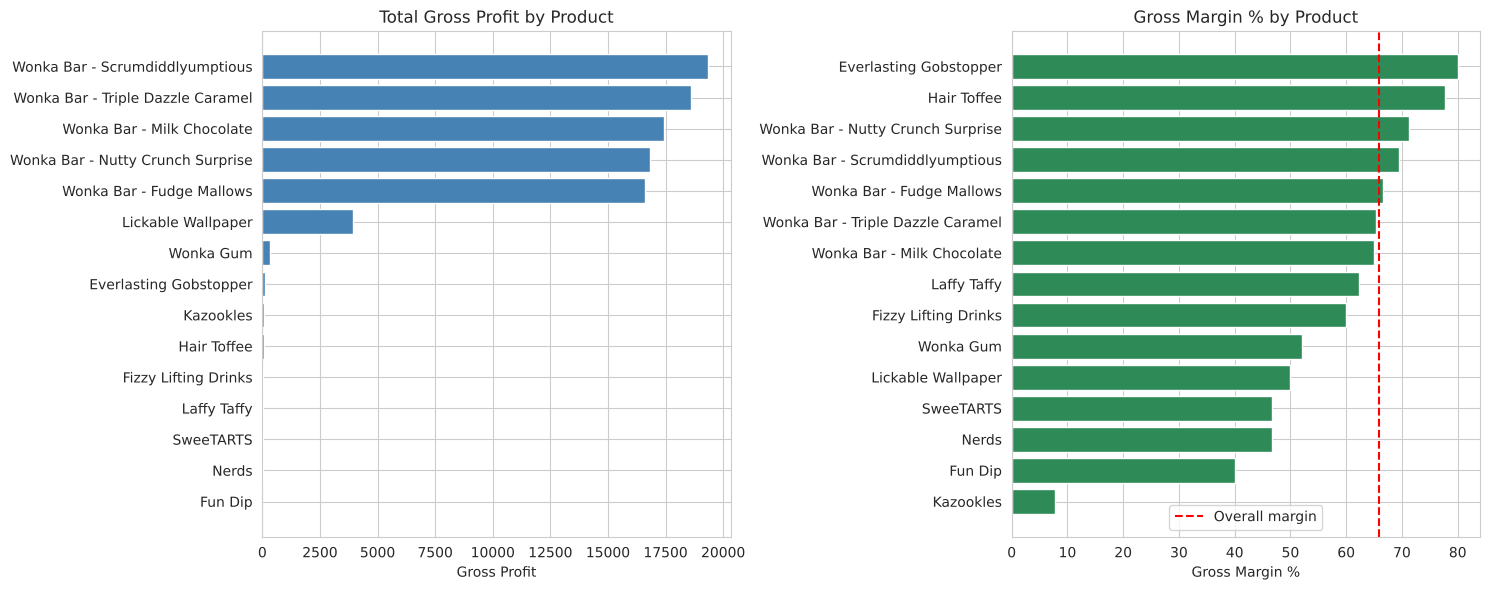

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

p1 = product.sort_values("Gross_Profit")
axes[0].barh(p1["Product Name"], p1["Gross_Profit"], color="steelblue")
axes[0].set_title("Total Gross Profit by Product")
axes[0].set_xlabel("Gross Profit")

p2 = product.sort_values("Margin %")
axes[1].barh(p2["Product Name"], p2["Margin %"], color="seagreen")
axes[1].axvline(total_profit / total_sales * 100, color="red", linestyle="--", label="Overall margin")
axes[1].set_title("Gross Margin % by Product")
axes[1].set_xlabel("Gross Margin %")
axes[1].legend()

plt.tight_layout()
plt.show()

Sales and profit are very different in size across products, so a table and bar chart are easier to read than one combined chart. The red line is the company's overall margin.

### 4.2 Margin volatility

Monthly margin is calculated for each product, and the standard deviation of those monthly margins is the volatility. I also check whether price and cost per unit change from order to order.

In [14]:
df["Month"] = df["Order Date"].dt.to_period("M")

monthly = df.groupby(["Product Name", "Month"]).agg(Sales=("Sales", "sum"), Profit=("Gross Profit", "sum")).reset_index()
monthly["Monthly Margin %"] = monthly["Profit"] / monthly["Sales"] * 100

volatility = monthly.groupby("Product Name").agg(
    Months_Sold=("Month", "count"),
    Avg_Monthly_Margin=("Monthly Margin %", "mean"),
    Margin_Volatility=("Monthly Margin %", "std")
).reset_index()
volatility["Margin_Volatility"] = volatility["Margin_Volatility"].round(2)

# products sold in fewer than 2 months have no std. deviation
product = product.merge(volatility[["Product Name", "Months_Sold", "Margin_Volatility"]], on="Product Name", how="left")
volatility.sort_values("Avg_Monthly_Margin", ascending=False)

,Product Name,Months_Sold,Avg_Monthly_Margin,Margin_Volatility
0,Everlasting Gobstopper,3,80.00,0.00
3,Hair Toffee,3,77.78,0.00
11,Wonka Bar - Nutty Crunch Surprise,24,71.35,0.00
12,Wonka Bar - Scrumdiddlyumptious,24,69.44,0.00
9,Wonka Bar - Fudge Mallows,24,66.67,0.00
13,Wonka Bar - Triple Dazzle Caramel,24,65.33,0.00
10,Wonka Bar - Milk Chocolate,24,64.92,0.00
5,Laffy Taffy,7,62.31,0.00
1,Fizzy Lifting Drinks,5,60.00,0.00
14,Wonka Gum,24,52.00,0.00


In [15]:
# is the price or cost per unit changing between orders?
df["Price per Unit"] = (df["Sales"] / df["Units"]).round(2)
df["Cost per Unit"] = (df["Cost"] / df["Units"]).round(2)

price_check = df.groupby("Product Name").agg(
    Min_Price=("Price per Unit", "min"), Max_Price=("Price per Unit", "max"),
    Min_Cost=("Cost per Unit", "min"), Max_Cost=("Cost per Unit", "max")
)
print("Products whose price changes:", (price_check["Min_Price"] != price_check["Max_Price"]).sum())
print("Products whose unit cost changes:", (price_check["Min_Cost"] != price_check["Max_Cost"]).sum())
price_check

Products whose price changes: 0
Products whose unit cost changes: 0


,Min_Price,Max_Price,Min_Cost,Max_Cost
Product Name,,,,
Everlasting Gobstopper,10.00,10.00,2.00,2.00
Fizzy Lifting Drinks,3.75,3.75,1.50,1.50
Fun Dip,1.50,1.50,0.90,0.90
Hair Toffee,4.50,4.50,1.00,1.00
Kazookles,3.25,3.25,3.00,3.00
Laffy Taffy,1.99,1.99,0.75,0.75
Lickable Wallpaper,20.00,20.00,10.00,10.00
Nerds,1.50,1.50,0.80,0.80
SweeTARTS,1.50,1.50,0.80,0.80


Margin volatility is 0 for every product. Each product is sold at one fixed price with one fixed unit cost, so its margin never moves over time. This means margin differences in this data come only from **which product** is sold, not from discounts or cost changes over time. It also means a weak product stays weak until its price or cost is changed.

In [16]:
# sales and profit by year, to see the trend
df["Year"] = df["Order Date"].dt.year
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Gross_Profit=("Gross Profit", "sum"), Units=("Units", "sum")).reset_index()
yearly["Margin %"] = yearly["Gross_Profit"] / yearly["Sales"] * 100
yearly

,Year,Sales,Gross_Profit,Units,Margin %
0,2024,"57,956.20","38,151.43",15899,65.83
1,2025,"83,827.43","55,291.37",22755,65.96


### 4.3 Product groups: profit vs sales vs margin
Every product is placed in one of four groups using the **median sales** and **median margin** of the 15 products as the cut-off.

In [17]:
median_sales = product["Sales"].median()
median_margin = product["Margin %"].median()
print("Median sales :", round(median_sales, 2))
print("Median margin:", round(median_margin, 2))

def get_group(row):
    high_sales = row["Sales"] >= median_sales
    high_margin = row["Margin %"] >= median_margin
    if high_sales and high_margin:
        return "High sales / High margin"
    elif high_sales and not high_margin:
        return "High sales / Low margin"
    elif not high_sales and high_margin:
        return "Low sales / High margin"
    else:
        return "Low sales / Low margin"

product["Group"] = product.apply(get_group, axis=1)

for g in ["High sales / High margin", "High sales / Low margin", "Low sales / High margin", "Low sales / Low margin"]:
    print()
    print(g)
    display(product[product["Group"] == g][["Product Name", "Sales", "Gross_Profit", "Margin %"]].reset_index(drop=True))

Median sales : 597.5
Median margin: 62.31

High sales / High margin


,Product Name,Sales,Gross_Profit,Margin %
0,Wonka Bar - Scrumdiddlyumptious,"27,874.80","19,357.50",69.44
1,Wonka Bar - Triple Dazzle Caramel,"28,485.00","18,610.20",65.33
2,Wonka Bar - Milk Chocolate,"26,867.75","17,443.37",64.92
3,Wonka Bar - Nutty Crunch Surprise,"23,574.95","16,819.95",71.35
4,Wonka Bar - Fudge Mallows,"24,890.40","16,593.60",66.67



High sales / Low margin


,Product Name,Sales,Gross_Profit,Margin %
0,Lickable Wallpaper,"7,860.00","3,930.00",50.00
1,Wonka Gum,597.50,310.70,52.00
2,Kazookles,"1,205.75",92.75,7.69



Low sales / High margin


,Product Name,Sales,Gross_Profit,Margin %
0,Everlasting Gobstopper,130.00,104.00,80.00
1,Hair Toffee,76.50,59.50,77.78
2,Laffy Taffy,53.73,33.48,62.31



Low sales / Low margin


,Product Name,Sales,Gross_Profit,Margin %
0,Fizzy Lifting Drinks,78.75,47.25,60.00
1,SweeTARTS,61.50,28.70,46.67
2,Nerds,15.00,7.00,46.67
3,Fun Dip,12.00,4.80,40.00


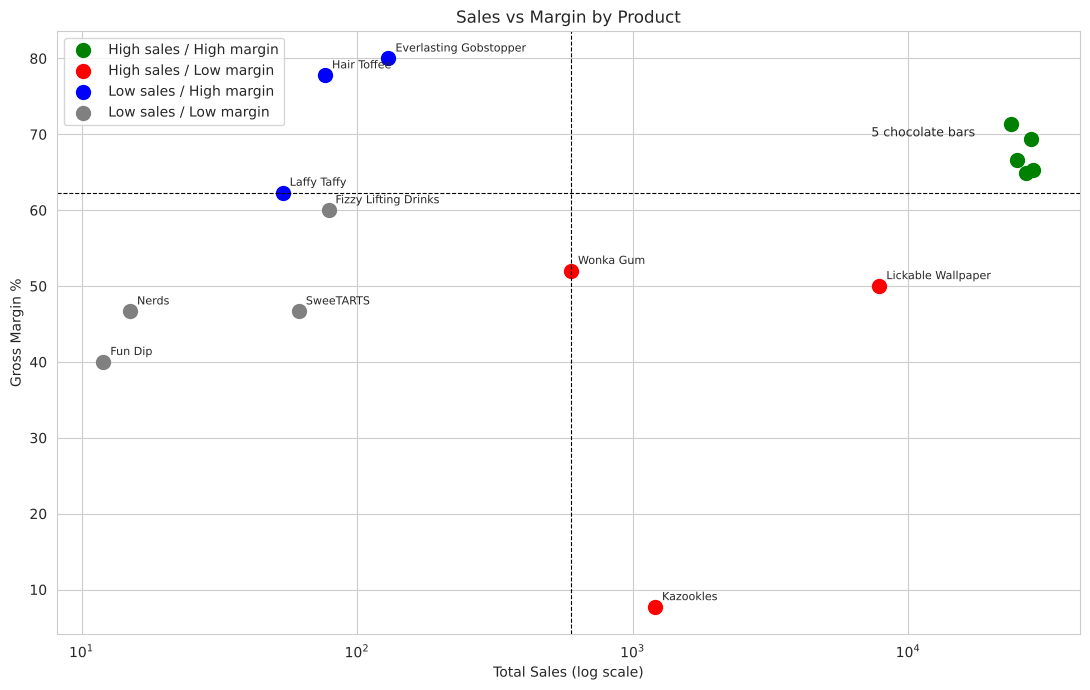

In [18]:
colors = {
    "High sales / High margin": "green",
    "High sales / Low margin": "red",
    "Low sales / High margin": "blue",
    "Low sales / Low margin": "grey",
}

plt.figure(figsize=(11, 7))
for g, c in colors.items():
    d = product[product["Group"] == g]
    plt.scatter(d["Sales"], d["Margin %"], s=100, color=c, label=g)

# label every product except the 5 chocolate bars (they sit very close together, so they get one label)
for _, r in product.iterrows():
    if r["Division"] != "Chocolate":
        plt.annotate(r["Product Name"], (r["Sales"], r["Margin %"]),
                     textcoords="offset points", xytext=(5, 5), fontsize=8)
choc = product[product["Division"] == "Chocolate"]
plt.annotate("5 chocolate bars", (choc["Sales"].mean(), choc["Margin %"].mean()),
             textcoords="offset points", xytext=(-110, 12), fontsize=9)

plt.axvline(median_sales, color="black", linestyle="--", linewidth=0.8)
plt.axhline(median_margin, color="black", linestyle="--", linewidth=0.8)
plt.xscale("log")
plt.xlabel("Total Sales (log scale)")
plt.ylabel("Gross Margin %")
plt.title("Sales vs Margin by Product")
plt.legend()
plt.tight_layout()
plt.show()

A log scale is used on the sales axis because the five chocolate bars sell thousands of times more than the smallest sugar products. Without it the small products would all sit on top of each other.

## 5. Division-level analysis

In [19]:
division = df.groupby("Division").agg(
    Products=("Product Name", "nunique"),
    Sales=("Sales", "sum"),
    Cost=("Cost", "sum"),
    Gross_Profit=("Gross Profit", "sum"),
    Units=("Units", "sum")
).reset_index()

division["Margin %"] = division["Gross_Profit"] / division["Sales"] * 100
division["Profit per Unit"] = division["Gross_Profit"] / division["Units"]
division["Revenue Share %"] = division["Sales"] / total_sales * 100
division["Profit Share %"] = division["Gross_Profit"] / total_profit * 100
division["Profit - Revenue Share (pts)"] = division["Profit Share %"] - division["Revenue Share %"]

division = division.sort_values("Sales", ascending=False).reset_index(drop=True)
division

,Division,Products,Sales,Cost,Gross_Profit,Units,Margin %,Profit per Unit,Revenue Share %,Profit Share %,Profit - Revenue Share (pts)
0,Chocolate,5,"131,692.90","42,868.28","88,824.62",37275,67.45,2.38,92.88,95.06,2.17
1,Other,4,"9,742.00","5,361.30","4,380.70",1263,44.97,3.47,6.87,4.69,-2.18
2,Sugar,6,348.73,111.25,237.48,116,68.10,2.05,0.25,0.25,0.01


In [20]:
# average of the order-level margins, for comparison with the weighted margin above
df["Row Margin %"] = df["Gross Profit"] / df["Sales"] * 100
avg_row_margin = df.groupby("Division")["Row Margin %"].mean().round(2)
print("Average order-level margin %:")
print(avg_row_margin)

Average order-level margin %:
Division
Chocolate   67.46
Other       38.10
Sugar       57.28
Name: Row Margin %, dtype: float64


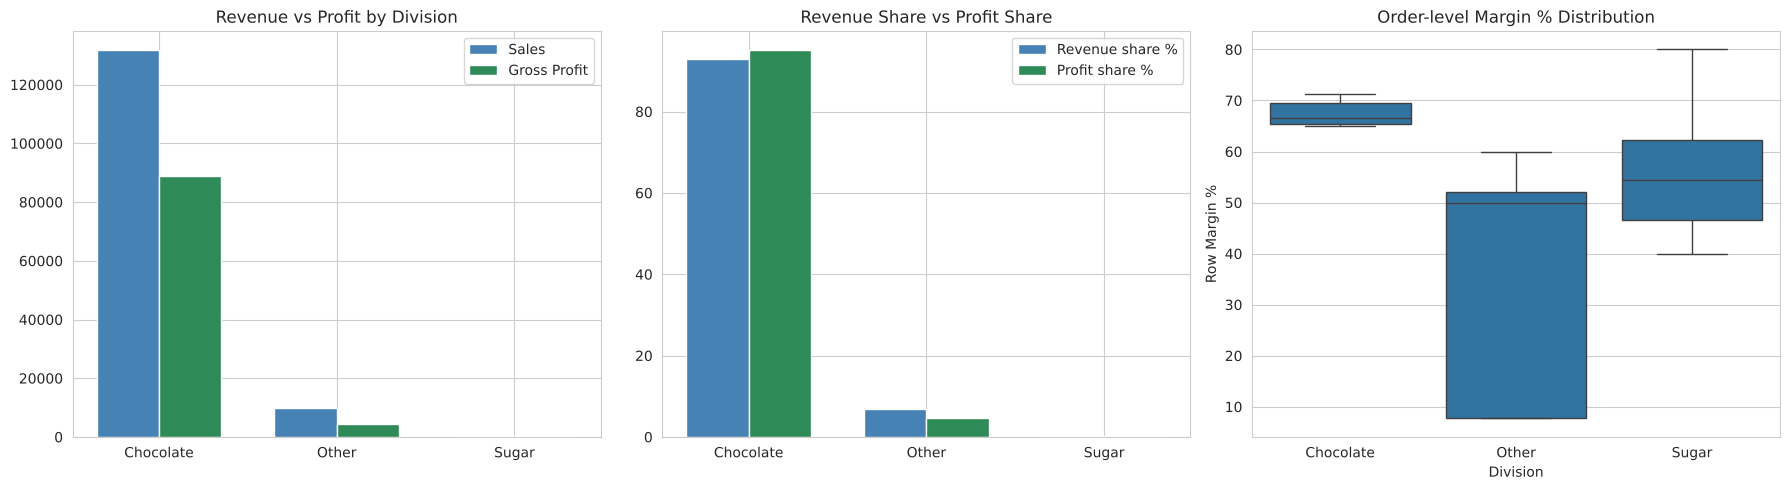

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# revenue vs profit
x = np.arange(len(division))
w = 0.35
axes[0].bar(x - w/2, division["Sales"], w, label="Sales", color="steelblue")
axes[0].bar(x + w/2, division["Gross_Profit"], w, label="Gross Profit", color="seagreen")
axes[0].set_xticks(x)
axes[0].set_xticklabels(division["Division"])
axes[0].set_title("Revenue vs Profit by Division")
axes[0].legend()

# revenue share vs profit share
axes[1].bar(x - w/2, division["Revenue Share %"], w, label="Revenue share %", color="steelblue")
axes[1].bar(x + w/2, division["Profit Share %"], w, label="Profit share %", color="seagreen")
axes[1].set_xticks(x)
axes[1].set_xticklabels(division["Division"])
axes[1].set_title("Revenue Share vs Profit Share")
axes[1].legend()

# margin distribution
sns.boxplot(data=df, x="Division", y="Row Margin %", order=division["Division"], ax=axes[2])
axes[2].set_title("Order-level Margin % Distribution")

plt.tight_layout()
plt.show()

In [22]:
# which products sit inside each division
product.sort_values(["Division", "Margin %"], ascending=[True, False])[["Division", "Product Name", "Sales", "Gross_Profit", "Margin %"]].reset_index(drop=True)

,Division,Product Name,Sales,Gross_Profit,Margin %
0,Chocolate,Wonka Bar - Nutty Crunch Surprise,"23,574.95","16,819.95",71.35
1,Chocolate,Wonka Bar - Scrumdiddlyumptious,"27,874.80","19,357.50",69.44
2,Chocolate,Wonka Bar - Fudge Mallows,"24,890.40","16,593.60",66.67
3,Chocolate,Wonka Bar - Triple Dazzle Caramel,"28,485.00","18,610.20",65.33
4,Chocolate,Wonka Bar - Milk Chocolate,"26,867.75","17,443.37",64.92
5,Other,Fizzy Lifting Drinks,78.75,47.25,60.00
6,Other,Wonka Gum,597.50,310.70,52.00
7,Other,Lickable Wallpaper,"7,860.00","3,930.00",50.00
8,Other,Kazookles,"1,205.75",92.75,7.69
9,Sugar,Everlasting Gobstopper,130.00,104.00,80.00


In [23]:
# the Other division has a low margin - how much of it is because of Kazookles?
other = df[df["Division"] == "Other"]
print("Other division margin %:", round(other["Gross Profit"].sum() / other["Sales"].sum() * 100, 2))

other_no_kaz = other[other["Product Name"] != "Kazookles"]
print("Other division margin % without Kazookles:", round(other_no_kaz["Gross Profit"].sum() / other_no_kaz["Sales"].sum() * 100, 2))

Other division margin %: 44.97
Other division margin % without Kazookles: 50.23


## 6. Profit concentration (Pareto) analysis

In [24]:
def pareto_table(col):
    t = product[["Product Name", col]].sort_values(col, ascending=False).reset_index(drop=True)
    t["Share %"] = t[col] / t[col].sum() * 100
    t["Cumulative %"] = t["Share %"].cumsum()
    return t

rev_p = pareto_table("Sales")
prof_p = pareto_table("Gross_Profit")

# number of products needed to reach 80%
n_rev = (rev_p["Cumulative %"] < 80).sum() + 1
n_prof = (prof_p["Cumulative %"] < 80).sum() + 1
n_total = len(product)

print(f"Products needed for 80% of revenue: {n_rev} of {n_total} ({n_rev / n_total * 100:.0f}% of products)")
print(f"Products needed for 80% of profit : {n_prof} of {n_total} ({n_prof / n_total * 100:.0f}% of products)")
print()
print("Revenue Pareto")
display(rev_p)
print("Profit Pareto")
display(prof_p)

Products needed for 80% of revenue: 5 of 15 (33% of products)
Products needed for 80% of profit : 5 of 15 (33% of products)

Revenue Pareto


,Product Name,Sales,Share %,Cumulative %
0,Wonka Bar - Triple Dazzle Caramel,"28,485.00",20.09,20.09
1,Wonka Bar - Scrumdiddlyumptious,"27,874.80",19.66,39.75
2,Wonka Bar - Milk Chocolate,"26,867.75",18.95,58.70
3,Wonka Bar - Fudge Mallows,"24,890.40",17.56,76.26
4,Wonka Bar - Nutty Crunch Surprise,"23,574.95",16.63,92.88
5,Lickable Wallpaper,"7,860.00",5.54,98.43
6,Kazookles,"1,205.75",0.85,99.28
7,Wonka Gum,597.50,0.42,99.70
8,Everlasting Gobstopper,130.00,0.09,99.79
9,Fizzy Lifting Drinks,78.75,0.06,99.85


Profit Pareto


,Product Name,Gross_Profit,Share %,Cumulative %
0,Wonka Bar - Scrumdiddlyumptious,"19,357.50",20.72,20.72
1,Wonka Bar - Triple Dazzle Caramel,"18,610.20",19.92,40.63
2,Wonka Bar - Milk Chocolate,"17,443.37",18.67,59.30
3,Wonka Bar - Nutty Crunch Surprise,"16,819.95",18.00,77.30
4,Wonka Bar - Fudge Mallows,"16,593.60",17.76,95.06
5,Lickable Wallpaper,"3,930.00",4.21,99.26
6,Wonka Gum,310.70,0.33,99.60
7,Everlasting Gobstopper,104.00,0.11,99.71
8,Kazookles,92.75,0.10,99.81
9,Hair Toffee,59.50,0.06,99.87


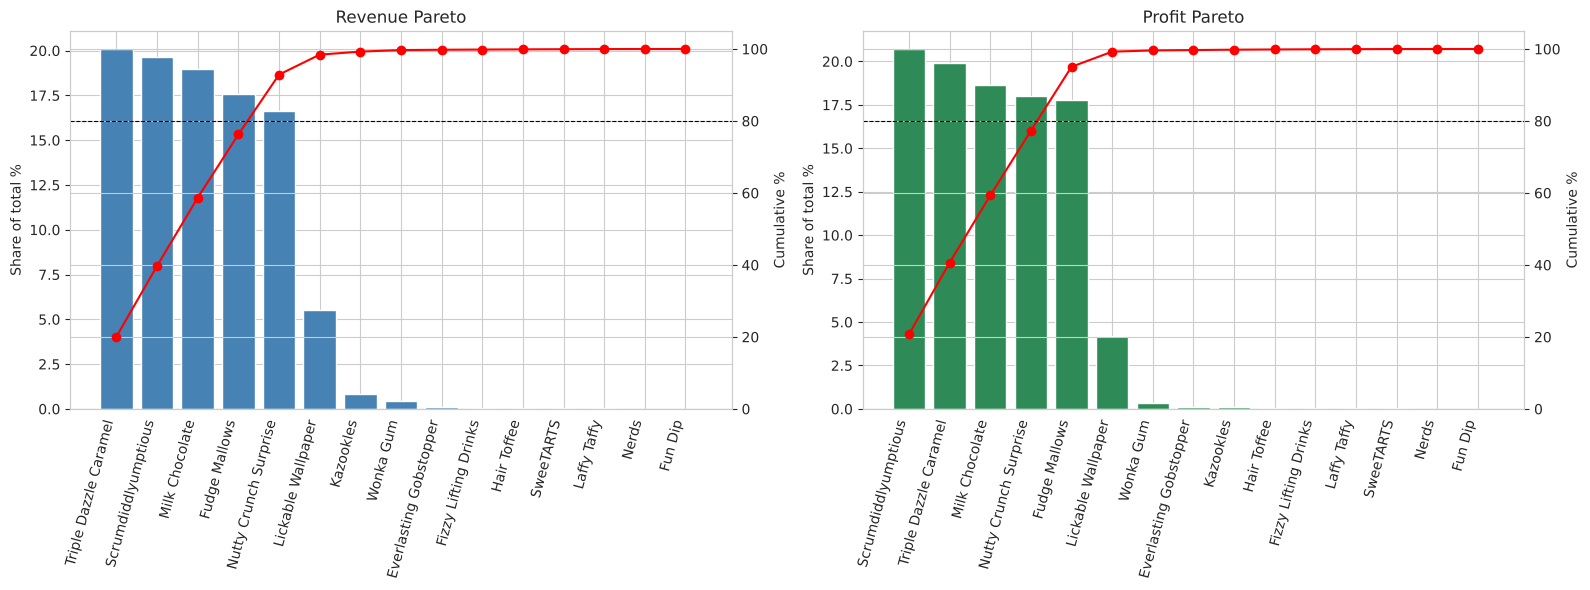

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, t, title, col in [(axes[0], rev_p, "Revenue Pareto", "steelblue"), (axes[1], prof_p, "Profit Pareto", "seagreen")]:
    ax.bar(range(len(t)), t["Share %"], color=col)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([n.replace("Wonka Bar - ", "") for n in t["Product Name"]], rotation=75, ha="right")
    ax.set_ylabel("Share of total %")
    ax.set_title(title)
    ax2 = ax.twinx()
    ax2.plot(range(len(t)), t["Cumulative %"], color="red", marker="o")
    ax2.axhline(80, color="black", linestyle="--", linewidth=0.8)
    ax2.set_ylim(0, 105)
    ax2.set_ylabel("Cumulative %")

plt.tight_layout()
plt.show()

In [26]:
# dependency indicators
print("Top 1 product share of profit  :", round(prof_p["Share %"].iloc[0], 2), "%")
print("Top 3 products share of profit :", round(prof_p["Share %"].iloc[:3].sum(), 2), "%")
print("Top 5 products share of profit :", round(prof_p["Share %"].iloc[:5].sum(), 2), "%")
print()
print("Chocolate division share of revenue:", round(division.loc[division["Division"] == "Chocolate", "Revenue Share %"].values[0], 2), "%")
print("Chocolate division share of profit :", round(division.loc[division["Division"] == "Chocolate", "Profit Share %"].values[0], 2), "%")

Top 1 product share of profit  : 20.72 %
Top 3 products share of profit : 59.3 %
Top 5 products share of profit : 95.06 %

Chocolate division share of revenue: 92.88 %
Chocolate division share of profit : 95.06 %


### Factory view (extra)

In [27]:
factory = df.groupby("Factory").agg(
    Products=("Product Name", "nunique"),
    Sales=("Sales", "sum"),
    Gross_Profit=("Gross Profit", "sum")
).reset_index()
factory["Margin %"] = factory["Gross_Profit"] / factory["Sales"] * 100
factory["Profit Share %"] = factory["Gross_Profit"] / total_profit * 100
factory.sort_values("Gross_Profit", ascending=False).reset_index(drop=True)

,Factory,Products,Sales,Gross_Profit,Margin %,Profit Share %
0,Lot's O' Nuts,3,"76,340.15","52,771.05",69.13,56.47
1,Wicked Choccy's,2,"55,352.75","36,053.57",65.13,38.58
2,Secret Factory,3,"8,587.50","4,344.70",50.59,4.65
3,The Other Factory,2,"1,282.25",152.25,11.87,0.16
4,Sugar Shack,5,220.98,121.23,54.86,0.13


## 7. Cost structure diagnostics

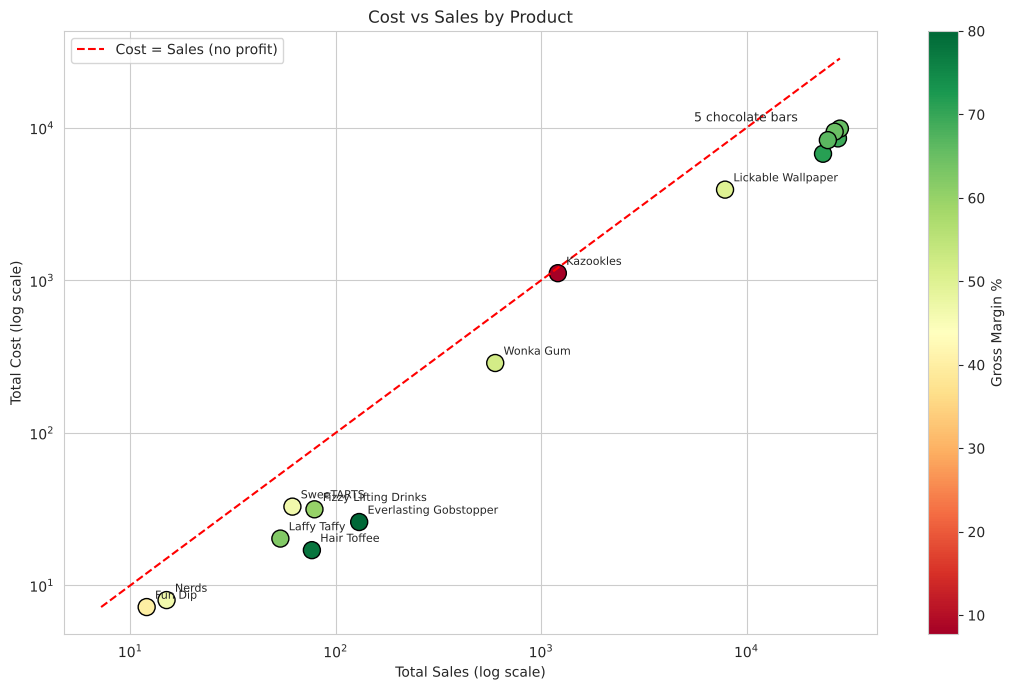

In [28]:
# cost vs sales scatter, bubble colour = margin
plt.figure(figsize=(11, 7))
sc = plt.scatter(product["Sales"], product["Cost"], c=product["Margin %"], cmap="RdYlGn", s=150, edgecolor="black")
plt.colorbar(sc, label="Gross Margin %")

for _, r in product.iterrows():
    if r["Division"] != "Chocolate":
        plt.annotate(r["Product Name"], (r["Sales"], r["Cost"]),
                     textcoords="offset points", xytext=(6, 6), fontsize=8)
choc = product[product["Division"] == "Chocolate"]
plt.annotate("5 chocolate bars", (choc["Sales"].mean(), choc["Cost"].mean()),
             textcoords="offset points", xytext=(-100, 12), fontsize=9)

# line where cost = sales (zero profit)
lim = [min(product["Sales"].min(), product["Cost"].min()), product["Sales"].max()]
plt.plot(lim, lim, color="red", linestyle="--", label="Cost = Sales (no profit)")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Total Sales (log scale)")
plt.ylabel("Total Cost (log scale)")
plt.title("Cost vs Sales by Product")
plt.legend()
plt.tight_layout()
plt.show()

Products close to the red line spend almost as much on cost as they earn in sales. Products far below it have a healthy margin.

Now I flag the risky products using simple rules:
- Margin below the cut-off (55%) and sales below the median -> **Discontinuation review**
- Margin below the cut-off, sales at or above the median, and cost per unit above the median -> **Cost renegotiation**
- Margin below the cut-off, sales at or above the median, and cost per unit not above the median -> **Repricing** (the cost is fine, the price is too low)

The 55% cut-off is used because all five chocolate bars are above 64%, so anything under 55% is clearly weaker. The cut-off can be changed in the code below.

In [29]:
MARGIN_CUTOFF = 55   # change this to test other thresholds

median_cost_per_unit = product["Cost per Unit"].median()

def get_flag(row):
    if row["Margin %"] >= MARGIN_CUTOFF:
        return "OK"
    if row["Sales"] < median_sales:
        return "Discontinuation review"
    if row["Cost per Unit"] > median_cost_per_unit:
        return "Cost renegotiation"
    return "Repricing"

product["Risk Flag"] = product.apply(get_flag, axis=1)

print("Median cost per unit:", round(median_cost_per_unit, 2))
product[["Product Name", "Division", "Sales", "Price per Unit", "Cost per Unit", "Margin %", "Risk Flag"]].sort_values("Margin %").reset_index(drop=True)

Median cost per unit: 1.1


,Product Name,Division,Sales,Price per Unit,Cost per Unit,Margin %,Risk Flag
0,Kazookles,Other,"1,205.75",3.25,3.00,7.69,Cost renegotiation
1,Fun Dip,Sugar,12.00,1.50,0.90,40.00,Discontinuation review
2,Nerds,Sugar,15.00,1.50,0.80,46.67,Discontinuation review
3,SweeTARTS,Sugar,61.50,1.50,0.80,46.67,Discontinuation review
4,Lickable Wallpaper,Other,"7,860.00",20.00,10.00,50.00,Cost renegotiation
5,Wonka Gum,Other,597.50,1.25,0.60,52.00,Repricing
6,Fizzy Lifting Drinks,Other,78.75,3.75,1.50,60.00,OK
7,Laffy Taffy,Sugar,53.73,1.99,0.75,62.31,OK
8,Wonka Bar - Milk Chocolate,Chocolate,"26,867.75",3.25,1.14,64.92,OK
9,Wonka Bar - Triple Dazzle Caramel,Chocolate,"28,485.00",3.75,1.30,65.33,OK


In [30]:
flagged = product[product["Risk Flag"] != "OK"]
print("Products flagged:", len(flagged), "of", len(product))
print()
print("Share of total revenue and profit by flag")
product.groupby("Risk Flag")[["Revenue Contribution %", "Profit Contribution %"]].sum()

Products flagged: 6 of 15

Share of total revenue and profit by flag


,Revenue Contribution %,Profit Contribution %
Risk Flag,,
Cost renegotiation,6.39,4.31
Discontinuation review,0.06,0.04
OK,93.12,95.32
Repricing,0.42,0.33


## 8. Key findings and recommendations

### Summary of results
- Total sales are **141,784**, gross profit is **93,443** and the overall gross margin is **65.9%** (10,194 orders, 2024-2025). No rows had to be removed. The data was already clean, apart from one product name spacing issue and one division label that differs from the brief (Fizzy Lifting Drinks).
- **Which products drive profit:** the five Wonka chocolate bars give **95.1%** of all gross profit and 92.9% of revenue. Wonka Bar - Scrumdiddlyumptious is the top profit product (19,358, 20.7% of profit). Nutty Crunch Surprise has the best chocolate margin (71.3%).
- **Are high-sales products profitable?** The chocolate bars are, with margins between 64.9% and 71.3%. The exceptions are in the *Other* division: **Kazookles** and **Lickable Wallpaper**.
- **Margin risk:**
  - **Kazookles** sells for 3.25 per unit and costs 3.00, so the margin is only **7.7%** and profit is 0.25 per unit. It has the 7th highest revenue (1,206) but gives just 0.10% of profit.
  - **Lickable Wallpaper** is the 6th largest product by sales (7,860) but earns a 50% margin, below every chocolate bar. It also has by far the highest unit cost (10.00).
  - **Wonka Gum** has a 52% margin on a low price (1.25 per unit).
- **Division view:** *Chocolate* earns a bigger share of profit (95.1%) than of revenue (92.9%), so it is efficient. *Other* earns a smaller share of profit (4.7%) than of revenue (6.9%), and its margin is only 45.0%. Without Kazookles the Other division margin would be 50.2%, so Kazookles is the main reason, but Lickable Wallpaper and Wonka Gum are also below the chocolate level. *Sugar* has a good margin (68.1%) but is only 0.25% of revenue.
- **Pareto:** 5 of 15 products (33%) make up 80% of revenue and the same 5 make up 80% of profit. The top 3 products alone give 59.3% of profit. The business depends heavily on the chocolate range.
- **Margin volatility is 0 for every product.** Each product has one fixed price and one fixed unit cost, so margins do not change over time. Weak margins are a pricing or sourcing problem that stays until it is fixed, not a temporary one. Sales grew from 57,956 in 2024 to 83,827 in 2025 while the margin stayed about 66%.
- **Factories:** Lot's O' Nuts (69.1% margin) and Wicked Choccy's (65.1%) produce 95% of profit. The Other Factory (Hair Toffee and Kazookles) has an 11.9% margin because of Kazookles.

### Recommendations
1. **Kazookles - cost renegotiation first, then repricing.** At 3.00 cost and 3.25 price there is almost no room. Either cut the unit cost with the supplier or raise the price. For example, a price of 4.25 (up by 1.00) would lift the margin to about 29%. If neither is possible, review whether to keep it.
2. **Lickable Wallpaper - cost renegotiation.** It is a real seller (5.5% of revenue), so it is worth keeping, but a 10.00 unit cost on a 20.00 price is high compared with the other products.
3. **Wonka Gum - repricing.** The unit cost (0.60) is low, but the 1.25 price leaves only a 52% margin. A price of about 1.70 would give it a margin similar to the chocolate bars (around 65%).
4. **Fun Dip, Nerds, SweeTARTS - discontinuation review.** Each has low sales and a margin below 50%. They give only 0.04% of profit together, so dropping them would hardly affect profit and would simplify the range.
5. **Protect the chocolate range.** It earns 95% of profit, so any supply, price or demand problem there hits the whole company. Growing the other divisions (for example the high-margin Gobstopper and Hair Toffee, which sell very little) would reduce this dependency.

### Limitations
- The margin is the same on every order of a product, so there is no discount or cost effect to analyse.
- Many Sugar products have very few orders (3 to 10), so their results are not reliable.
- The 55% margin cut-off and the median-based groups are my own choices. The flags change if the cut-off is changed.
- Ship dates look wrong and were not used.